# Класифікація грибів за табличними ознаками

Датасет: [Mushroom Classification](https://www.kaggle.com/datasets/uciml/mushroom-classification), 8124 записи, 22 категоріальні ознаки. Ціль: `e = 0` — їстівний, `p = 1` — отруйний.

Моделі: BernoulliNB, Decision Tree, Random Forest.

In [1]:
# %pip install pandas numpy scikit-learn matplotlib seaborn

In [2]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, RocCurveDisplay,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.14.7
pandas: 3.1.0
scikit-learn: 1.9.1


## Перевірка даних

`?` позначає пропуск. Перевіряємо кількість записів, дублікати, пропуски та розподіл класів.

In [3]:
DATA_PATH = Path("mushrooms.csv")
df = pd.read_csv(DATA_PATH, na_values=["?"])
assert set(df["class"].unique()) == {"e", "p"}
print(f"Записів: {len(df):,}; вхідних ознак: {df.shape[1] - 1}")
print("Повних дублікатів:", df.duplicated().sum())
display(df.head())

summary = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропуски": df.isna().sum(),
    "пропуски_%": (df.isna().mean() * 100).round(2),
    "кількість_категорій": df.nunique(),
})
display(summary)

Записів: 8,124; вхідних ознак: 22
Повних дублікатів: 0


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


,тип,пропуски,пропуски_%,кількість_категорій
class,str,0,0.00,2
cap-shape,str,0,0.00,6
cap-surface,str,0,0.00,4
cap-color,str,0,0.00,10
bruises,str,0,0.00,2
odor,str,0,0.00,9
gill-attachment,str,0,0.00,2
gill-spacing,str,0,0.00,2
gill-size,str,0,0.00,2
gill-color,str,0,0.00,12


,кількість,частка_%
class,,
e,4208,51.8
p,3916,48.2


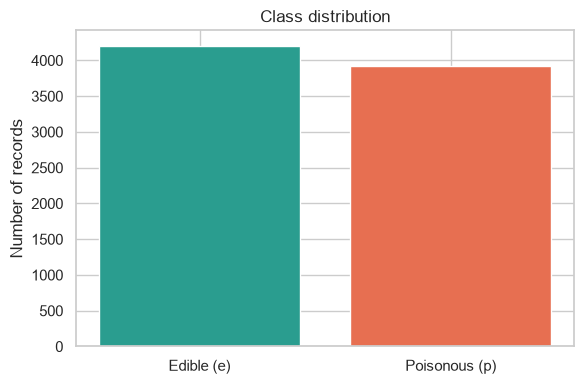

In [4]:
counts = df["class"].value_counts().reindex(["e", "p"])
display(pd.DataFrame({"кількість": counts, "частка_%": (100 * counts / len(df)).round(2)}))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Edible (e)", "Poisonous (p)"], counts, color=["#2a9d8f", "#e76f51"])
ax.set(title="Class distribution", ylabel="Number of records")
plt.tight_layout()
plt.show()

## Поділ даних

Train — 80% (6499 записів), test — 20% (1625). Стратифікація зберігає пропорції класів; `random_state=42`. Позитивний клас — отруйний (`1`).

In [ ]:
X = df.drop(columns="class")
y = df["class"].map({"e": 0, "p": 1})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)
display(pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
}).rename(index={0: "їстівний", 1: "отруйний"}))
constant_columns = X_train.columns[X_train.nunique(dropna=False) == 1].tolist()
feature_columns = [column for column in X_train.columns if column not in constant_columns]

Навчальна вибірка: (6499, 22)
Тестова вибірка: (1625, 22)


,train,test
class,,
їстівний,3366,842
отруйний,3133,783


Сталі ознаки, визначені на train: ['veil-type']


## Підготовка ознак

Пропуски замінюємо категорією `missing`; категорії кодуємо one-hot. Сталу ознаку `veil-type` вилучаємо за train. Перетворення виконуються в `Pipeline` усередині CV. BernoulliNB працює з отриманими бінарними ознаками.

In [6]:
categorical_pipeline = Pipeline([
    ("missing", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("categories", categorical_pipeline, feature_columns)
], remainder="drop")

def make_pipeline(model):
    return Pipeline([("preprocess", clone(preprocessor)), ("model", model)])

## Моделі та параметри

`GridSearchCV` обирає параметри за F1 класу 1 на п'яти стратифікованих фолдах train (`shuffle=True`, seed 42).

- BernoulliNB: `alpha ∈ {0.1, 1, 10}`.
- Decision Tree: `max_depth ∈ {3, 6, None}`, `min_samples_leaf ∈ {1, 5}`.
- Random Forest: 150 дерев, `max_depth ∈ {8, None}`, `min_samples_leaf ∈ {1, 3}`.

Модель обираємо за середнім CV-F1 до оцінювання test.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
experiments = {
    "Naive Bayes (Bernoulli)": (
        BernoulliNB(), {"model__alpha": [0.1, 1.0, 10.0]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 6, None], "model__min_samples_leaf": [1, 5]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1),
        {"model__max_depth": [8, None], "model__min_samples_leaf": [1, 3]},
    ),
}
searches = {}
cv_rows = []
for name, (model, parameters) in experiments.items():
    search = GridSearchCV(
        make_pipeline(model), parameters, scoring="f1", cv=cv,
        n_jobs=2, return_train_score=False, error_score="raise"
    )
    search.fit(X_train, y_train)
    searches[name] = search
    cv_rows.append({
        "model": name,
        "CV_F1_mean": search.best_score_,
        "CV_F1_std": search.cv_results_["std_test_score"][search.best_index_],
        "best_parameters": search.best_params_,
    })
    print(name, "завершено")

cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("CV_F1_mean", ascending=False)
display(cv_results)
selected_name = cv_results.index[0]
selected_model = searches[selected_name].best_estimator_
print("Модель, обрана за CV до оцінювання на тесті:", selected_name)

Naive Bayes (Bernoulli) завершено
Decision Tree завершено
Random Forest завершено


,CV_F1_mean,CV_F1_std,best_parameters
model,,,
Random Forest,1.000000,0.000000,"{'model__max_depth': None, 'model__min_samples..."
Decision Tree,0.999681,0.000639,"{'model__max_depth': 6, 'model__min_samples_le..."
Naive Bayes (Bernoulli),0.951744,0.010850,{'model__alpha': 0.1}


Модель, обрана за CV до оцінювання на тесті: Random Forest


## Результати на test

Однакові тестові записи для всіх моделей. Accuracy — частка правильних прогнозів; precision — частка правильних серед прогнозів класу 1; recall — частка знайдених прикладів класу 1; F1 поєднує precision і recall.

FN — помилки `1 → 0`, FP — `0 → 1`. Dummy завжди передбачає клас більшості.

In [8]:
fitted_models = {name: search.best_estimator_ for name, search in searches.items()}
dummy = make_pipeline(DummyClassifier(strategy="most_frequent"))
dummy.fit(X_train, y_train)
fitted_models["Dummy (majority)"] = dummy

test_rows = []
predictions = {}
for name, model in fitted_models.items():
    pred = model.predict(X_test)
    positive_index = list(model.classes_).index(1)
    probability = model.predict_proba(X_test)[:, positive_index]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    predictions[name] = (pred, probability)
    test_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_p": precision_score(y_test, pred, zero_division=0),
        "recall_p": recall_score(y_test, pred, zero_division=0),
        "F1_p": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probability),
        "average_precision": average_precision_score(y_test, probability),
        "poisonous_as_edible_FN": int(fn),
        "edible_as_poisonous_FP": int(fp),
    })
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results.round(4))

,accuracy,precision_p,recall_p,F1_p,ROC_AUC,average_precision,poisonous_as_edible_FN,edible_as_poisonous_FP
model,,,,,,,,
Naive Bayes (Bernoulli),0.9582,0.9877,0.9246,0.9551,0.9976,0.9975,59,9
Decision Tree,0.9988,1.0000,0.9974,0.9987,0.9999,0.9999,2,0
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0,0
Dummy (majority),0.5182,0.0000,0.0000,0.0000,0.5000,0.4818,783,0


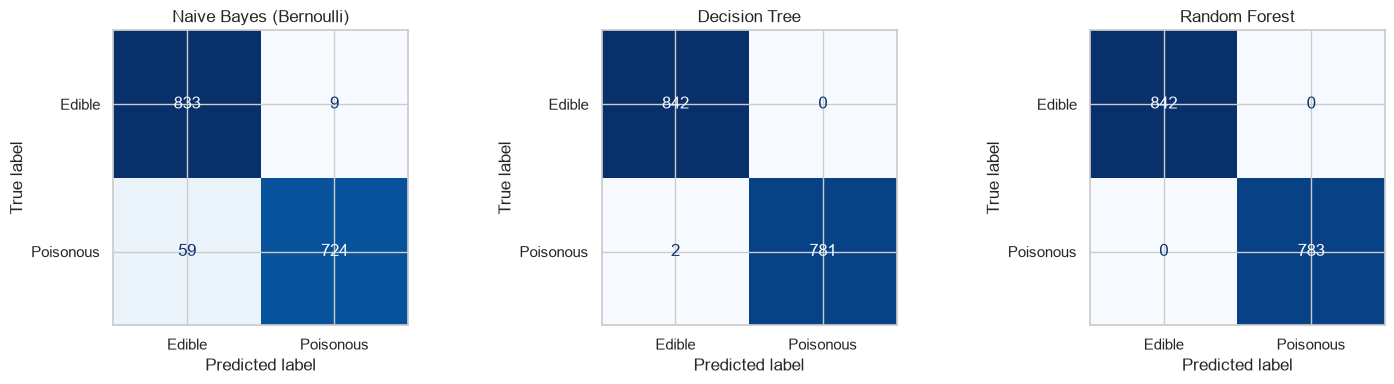

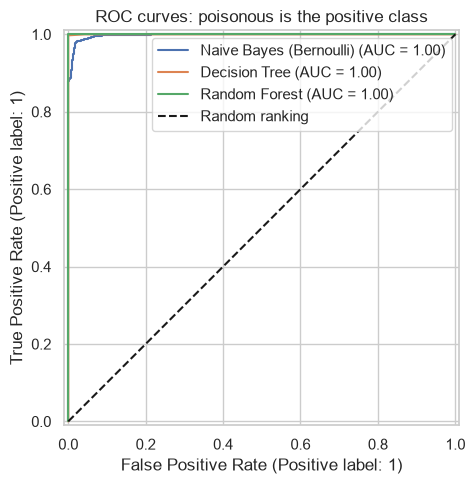

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, experiments):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name][0], labels=[0, 1],
        display_labels=["Edible", "Poisonous"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name in experiments:
    RocCurveDisplay.from_predictions(y_test, predictions[name][1], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random ranking")
ax.set_title("ROC curves: poisonous is the positive class")
ax.legend()
plt.tight_layout()
plt.show()

## Важливість ознак

Показано верхні рівні дерева та permutation importance обраної моделі на 1500 навчальних записах (5 перестановок, метрика F1). Більше падіння F1 означає більшу залежність прогнозів від ознаки.

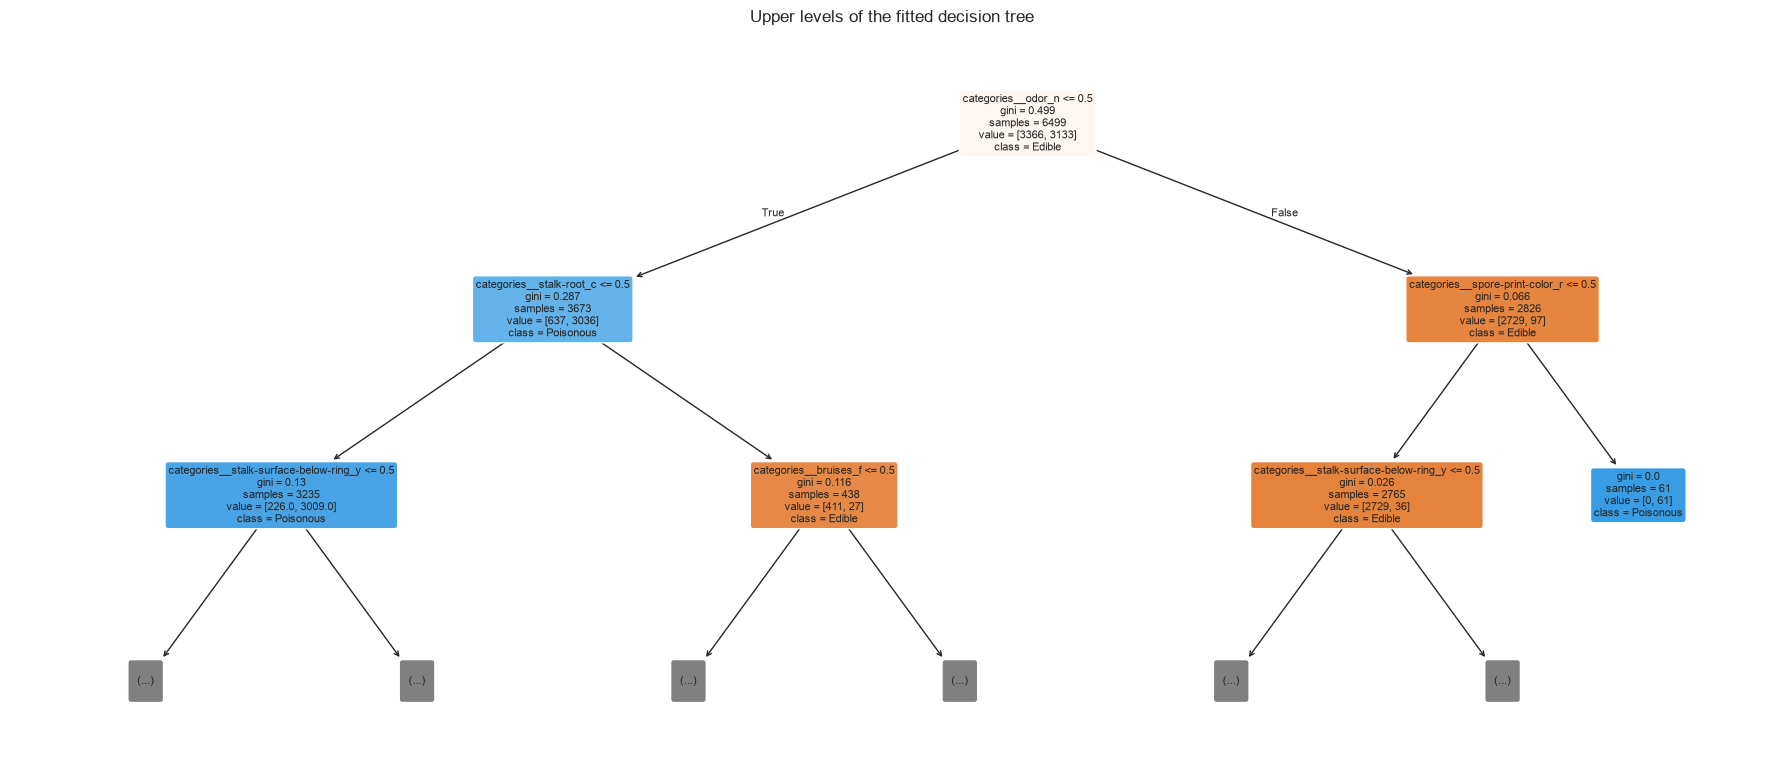

,feature,mean_F1_decrease,std
4,odor,0.012404,0.001329
7,gill-size,0.010424,0.000991
19,spore-print-color,0.002154,0.000788
2,cap-color,0.000000,0.000000
1,cap-surface,0.000000,0.000000
0,cap-shape,0.000000,0.000000
5,gill-attachment,0.000000,0.000000
3,bruises,0.000000,0.000000
8,gill-color,0.000000,0.000000
6,gill-spacing,0.000000,0.000000


In [10]:
tree_pipeline = fitted_models["Decision Tree"]
encoded_names = tree_pipeline.named_steps["preprocess"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    tree_pipeline.named_steps["model"], max_depth=2,
    feature_names=encoded_names, class_names=["Edible", "Poisonous"],
    filled=True, rounded=True, fontsize=8, ax=ax
)
ax.set_title("Upper levels of the fitted decision tree")
plt.tight_layout()
plt.show()

X_explain = X_train.sample(n=min(1500, len(X_train)), random_state=RANDOM_STATE)
y_explain = y_train.loc[X_explain.index]
importance = permutation_importance(
    selected_model, X_explain, y_explain, scoring="f1",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=2
)
importance_table = pd.DataFrame({
    "feature": X_train.columns,
    "mean_F1_decrease": importance.importances_mean,
    "std": importance.importances_std,
}).sort_values("mean_F1_decrease", ascending=False)
display(importance_table.head(10))

## Підсумок

Нижче наведено результати моделі, обраної за CV-F1.

In [ ]:
row = test_results.loc[selected_name]
display(Markdown(
    f"За середнім F1 у п'ятикратній перехресній перевірці обрано **{selected_name}** "
    f"(CV-F1 = **{cv_results.loc[selected_name, 'CV_F1_mean']:.4f}**). "
    f"На відкладеній тестовій вибірці: accuracy = **{row['accuracy']:.4f}**, "
    f"F1 для отруйного класу = **{row['F1_p']:.4f}**, "
    f"recall для отруйного класу = **{row['recall_p']:.4f}**. "
    f"Отруйних грибів, помилково названих їстівними: **{int(row['poisonous_as_edible_FN'])}**.\n\n"
    "Ці показники отримані на одному фіксованому поділі історичного датасету. "
    "Результати не можна безпосередньо порівнювати з числами зі статей без узгодження "
    "ознак, підготовки даних і способу перевірки."
))
print(classification_report(y_test, predictions[selected_name][0], target_names=["Edible", "Poisonous"], zero_division=0))

За середнім F1 у п'ятикратній перехресній перевірці обрано **Random Forest** (CV-F1 = **1.0000**). На відкладеній тестовій вибірці: accuracy = **1.0000**, F1 для отруйного класу = **1.0000**, recall для отруйного класу = **1.0000**. Отруйних грибів, помилково названих їстівними: **0**.

Ці показники отримані на одному фіксованому поділі історичного датасету. Результати не можна безпосередньо порівнювати з числами зі статей без узгодження ознак, підготовки даних і способу перевірки.

Звіт для обраної моделі:
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



## Джерела та межі результатів

Статті й зіставлення результатів наведені в [README](README.md#статті).

Оцінки стосуються одного поділу історичних табличних даних. Групування за видом не виконувалося; якість на нових видах не перевірялася.